# Séries temporais na Engenharia Elétrica
## Consumo residencial: análise, modelagem e previsão
Notebook para Google Colab, CPU, sem chave de API. Fonte: [UCI, Individual Household Electric Power Consumption](https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption), Hebrail e Berard, DOI 10.24432/C58K54, CC BY 4.0. São registros históricos de uma residência francesa, não dados atuais do sistema elétrico brasileiro.

**Objetivo:** estimar a energia do próximo dia usando informações disponíveis até o encerramento do dia anterior. O roteiro também explora tensão, corrente e submedições. Executar as células na ordem. Em Colab: Arquivo → Fazer upload de notebook → Ambiente de execução → Executar tudo. A primeira execução baixa cerca de 20 MB; o arquivo descompactado ocupa cerca de 130 MB. A execução pode levar alguns minutos.

**Mapa:** N01 ambiente; N02 aquisição; N03 auditoria; N04 agregação; N05 tratamento causal; N06 separação; N07 análise; N08 dependência; N09 atributos; N10 modelos; N11 validação; N12 teste; N13 diagnóstico; N14 múltiplos passos; N15 exportação; N16 atividades.

## N01 • Ambiente e parâmetros
A configuração centraliza as decisões que serão modificadas no estudo dirigido. `TESTE_DIAS` e `VALIDACAO_DIAS` definem blocos finais cronológicos. `LAGS` determina quantos dias anteriores alimentam os modelos de ML. A frequência diária reduz custo computacional e muda a pergunta: não se está prevendo o pico instantâneo de demanda.

In [1]:
import importlib.util, subprocess, sys
necessarios = {'statsmodels': 'statsmodels>=0.14,<0.15', 'sklearn': 'scikit-learn>=1.4,<2', 'pandas': 'pandas>=2.2,<3', 'matplotlib': 'matplotlib>=3.8,<4'}
faltantes = [pacote for modulo, pacote in necessarios.items() if importlib.util.find_spec(modulo) is None]
if faltantes:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *faltantes])
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import zipfile, urllib.request, warnings, json, platform
from pathlib import Path
from IPython.display import display
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit
from sklearn.base import clone
import sklearn, statsmodels
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True, 'grid.alpha': .25})
SEMENTE = 42
COBERTURA_MINIMA = .95
VALIDACAO_DIAS = 60
TESTE_DIAS = 60
HORIZONTE_FUTURO = 14
LAGS = [1, 2, 3, 7, 14, 21, 28]
JANELAS = [7, 28]
SAZONALIDADE = 7
PASTA = Path('series_eletricas'); PASTA.mkdir(exist_ok=True)
print({'Python': platform.python_version(), 'pandas': pd.__version__, 'sklearn': sklearn.__version__, 'statsmodels': statsmodels.__version__})

{'Python': '3.13.16', 'pandas': '2.2.3', 'sklearn': '1.6.1', 'statsmodels': '0.15.0'}


## N02 • Download público e leitura
O arquivo usa ponto e vírgula, data no formato dia/mês/ano e ausências que devem virar `NaN`. O download é armazenado para evitar repetir a transferência. Se a rede do Colab bloquear a UCI, baixar o ZIP no endereço da fonte e enviá-lo para `series_eletricas/power.zip`; executar novamente. Não se substituem medições reais por dados simulados.

As grandezas incluem potência ativa média de um minuto (kW), tensão (V), corrente (A) e energia de submedição (Wh por intervalo de um minuto). A fonte descreve potência reativa com unidade kW; há inconsistência de nomenclatura física, por isso essa coluna não será usada para calcular energia ativa.

In [2]:
URL = 'https://archive.ics.uci.edu/static/public/235/individual+household+electric+power+consumption.zip'
arquivo = PASTA / 'power.zip'
if not arquivo.exists():
    try:
        urllib.request.urlretrieve(URL, arquivo)
    except Exception as erro:
        arquivo.unlink(missing_ok=True)
        raise RuntimeError('Download indisponível. Envie o ZIP da UCI para series_eletricas/power.zip e execute novamente.') from erro
colunas = ['Date', 'Time', 'Global_active_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']
with zipfile.ZipFile(arquivo) as z:
    nome = next(n for n in z.namelist() if n.endswith('household_power_consumption.txt'))
    with z.open(nome) as f:
        bruto = pd.read_csv(f, sep=';', usecols=colunas, na_values=['?', ''], low_memory=False)
indice = pd.to_datetime(bruto.pop('Date') + ' ' + bruto.pop('Time'), format='%d/%m/%Y %H:%M:%S')
bruto.index = indice
bruto = bruto.apply(pd.to_numeric, errors='coerce').sort_index()
bruto.index.name = 'data_hora'
print('Registros:', len(bruto), '| início:', bruto.index.min(), '| fim:', bruto.index.max())
display(bruto.head())

Registros: 2075259 | início: 2006-12-16 17:24:00 | fim: 2010-11-26 21:02:00


,Global_active_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
data_hora,,,,,,
2006-12-16 17:24:00,4.216,234.84,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,5.360,233.63,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,5.374,233.29,23.0,0.0,2.0,17.0
2006-12-16 17:27:00,5.388,233.74,23.0,0.0,1.0,17.0
2006-12-16 17:28:00,3.666,235.68,15.8,0.0,1.0,17.0


## N03 • Auditoria de integridade
Não se confunde valor ausente com energia nula. Duplicatas conflitantes interrompem a execução; duplicatas idênticas podem ser removidas. O índice é regularizado em minutos e valores negativos de potência ativa são classificados como inválidos para este conjunto residencial de consumo. Essa regra não se aplica automaticamente a instalações com exportação fotovoltaica.

Os horários são tratados conforme o arquivo, sem impor conversão de fuso não documentada. Em aplicações reais, horário de verão e duração efetiva do dia exigem metadados próprios.

In [3]:
if bruto.index.has_duplicates:
    duplicados = bruto[bruto.index.duplicated(keep=False)]
    if duplicados.groupby(level=0).nunique(dropna=False).gt(1).any().any():
        raise ValueError('Há timestamps duplicados com valores conflitantes.')
    bruto = bruto[~bruto.index.duplicated()]
bruto = bruto.asfreq('min')
negativos = int(bruto['Global_active_power'].lt(0).sum())
bruto.loc[bruto['Global_active_power'] < 0, 'Global_active_power'] = np.nan
auditoria = pd.DataFrame({'ausentes': bruto.isna().sum(), 'percentual_ausente': 100 * bruto.isna().mean()})
print('Potências negativas invalidadas:', negativos)
display(auditoria.round(3))

Potências negativas invalidadas: 0


,ausentes,percentual_ausente
Global_active_power,25979,1.252
Voltage,25979,1.252
Global_intensity,25979,1.252
Sub_metering_1,25979,1.252
Sub_metering_2,25979,1.252
Sub_metering_3,25979,1.252


## N04 • Da potência à energia: agregação diária
Para medições completas, a energia diária é `sum(P_kW)/60`, pois cada amostra representa um minuto. Somar kW sem multiplicar pelo tempo é dimensionalmente incorreto. Para dias com ao menos 95% de observações válidas, o notebook estima energia de um dia completo por `mean(P_kW)*24`. Isso assume que os minutos ausentes são representativos do restante do dia e introduz incerteza de medição.

Dias com menos cobertura ficam sem alvo válido. O primeiro e o último dia parcial são excluídos. A cobertura e a energia efetivamente observada são mantidas para auditoria. Energia estimada não equivale a leitura integral de medidor.

Dias integrais no índice: 1440 | dias sem alvo: 23


,minutos_registrados,minutos_validos,energia_observada_kwh,potencia_media_kw,cobertura,energia_kwh,Voltage,Global_intensity,Sub_metering_1_kwh,Sub_metering_2_kwh,Sub_metering_3_kwh
data_hora,,,,,,,,,,,
2006-12-17,1440,1440,56.507667,2.354486,1.000000,56.507667,240.087028,9.999028,2.033000,4.187000,13.341000
2006-12-18,1440,1440,36.730433,1.530435,1.000000,36.730433,241.231694,6.421667,1.063000,2.621000,14.018000
2006-12-19,1440,1440,27.769900,1.157079,1.000000,27.769900,241.999313,4.926389,0.839000,7.602000,6.197000
2006-12-20,1440,1440,37.095800,1.545658,1.000000,37.095800,242.308062,6.467361,0.000000,2.648000,14.063000
2006-12-21,1440,1438,28.610400,1.193758,0.998611,28.650192,241.040549,5.033797,1.767455,2.626648,10.435494


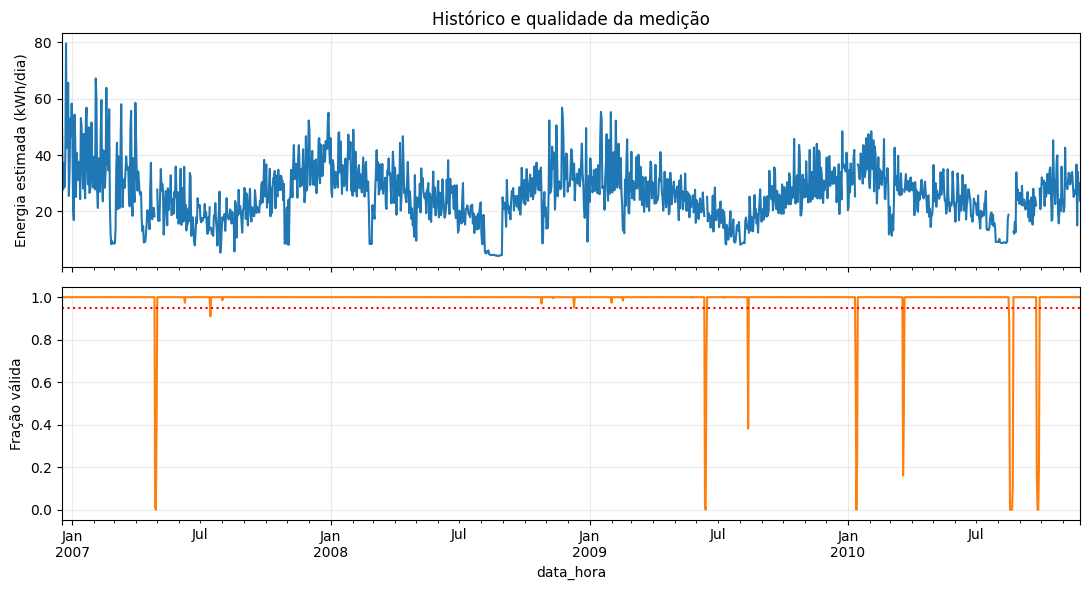

In [4]:
p = bruto['Global_active_power']
res = p.resample('D')
diario = pd.DataFrame({'minutos_registrados': res.size(), 'minutos_validos': res.count(), 'energia_observada_kwh': res.sum(min_count=1) / 60, 'potencia_media_kw': res.mean()})
diario = diario.loc[diario['minutos_registrados'].eq(1440)].copy()
diario['cobertura'] = diario['minutos_validos'] / 1440
diario['energia_kwh'] = (diario['potencia_media_kw'] * 24).where(diario['cobertura'] >= COBERTURA_MINIMA)
for coluna in ['Voltage', 'Global_intensity']:
    diario[coluna] = bruto[coluna].resample('D').mean().reindex(diario.index)
for coluna in ['Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']:
    contagem = bruto[coluna].resample('D').count().reindex(diario.index)
    diario[coluna + '_kwh'] = (bruto[coluna].resample('D').mean() * 1440 / 1000).reindex(diario.index).where(contagem / 1440 >= COBERTURA_MINIMA)
print('Dias integrais no índice:', len(diario), '| dias sem alvo:', diario.energia_kwh.isna().sum())
display(diario.head())
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
diario.energia_kwh.plot(ax=ax[0], ylabel='Energia estimada (kWh/dia)', title='Histórico e qualidade da medição')
diario.cobertura.plot(ax=ax[1], ylabel='Fração válida', color='tab:orange'); ax[1].axhline(COBERTURA_MINIMA, color='red', linestyle=':'); plt.tight_layout(); plt.show()

## N05 • Tratamento causal de lacunas
A série para modelagem precisa de frequência diária regular. Para um dia sem alvo, utiliza-se o valor preenchido de sete dias antes; se indisponível, utiliza-se o último dia conhecido. Essa imputação usa somente o passado. Não são usadas interpolação bilateral, preenchimento para trás ou média de toda a série.

Valores imputados podem alimentar o histórico, mas não são tratados como verdade na avaliação. A máscara `observado` preserva essa distinção. A análise de sensibilidade deve repetir o experimento com outra cobertura mínima.

In [5]:
observado = diario.energia_kwh.notna()
primeiro = diario.energia_kwh.first_valid_index()
diario = diario.loc[primeiro:].copy(); observado = observado.loc[primeiro:]
y = diario.energia_kwh.copy()
for i in range(len(y)):
    if pd.isna(y.iloc[i]):
        y.iloc[i] = y.iloc[i-7] if i >= 7 else y.iloc[i-1]
y = y.asfreq('D').rename('energia_kwh')
assert y.notna().all() and y.index.is_monotonic_increasing and not y.index.has_duplicates
print('Dias imputados:', int((~observado).sum()))

Dias imputados: 23


## N06 • Treino, validação e teste
O último bloco de 60 dias é teste; os 60 anteriores são validação. As análises que orientam decisões e a seleção de modelo usam apenas treino e validação. O teste é aberto uma vez para medir desempenho. Os gráficos anteriores descrevem qualidade do arquivo, sem selecionar modelos.

**Protocolo principal:** previsão de um dia à frente, emitida ao final do dia anterior. Após cada previsão, a medição daquele dia pode atualizar o histórico para o próximo. Não se utilizam o valor real do próprio alvo nem dias posteriores. Nos dias sem medição válida, entra apenas a imputação causal. A avaliação de vários dias será separada em N14.

In [6]:
assert len(y) > VALIDACAO_DIAS + TESTE_DIAS + max(LAGS) + 100
fim_treino = len(y) - VALIDACAO_DIAS - TESTE_DIAS
fim_validacao = len(y) - TESTE_DIAS
treino = y.iloc[:fim_treino]
validacao = y.iloc[fim_treino:fim_validacao]
teste = y.iloc[fim_validacao:]
for nome, bloco in [('treino', treino), ('validação', validacao), ('teste', teste)]:
    print(nome, bloco.index.min().date(), bloco.index.max().date(), len(bloco), 'dias; alvos válidos:', int(observado.loc[bloco.index].sum()))

treino 2006-12-17 2010-07-28 1320 dias; alvos válidos: 1307
validação 2010-07-29 2010-09-26 60 dias; alvos válidos: 52
teste 2010-09-27 2010-11-25 60 dias; alvos válidos: 58


## N07 • Exploração das séries elétricas
A análise temporal revela mudança de nível, extremos e ciclos que estatísticas isoladas ocultam. Média e desvio padrão continuam sendo medidas descritivas válidas sem normalidade; sua interpretação depende de assimetria, dependência e estabilidade temporal. Normalidade da série bruta não é condição universal para prever.

Os painéis usam apenas o período de treino. A comparação por dia da semana agrega anos diferentes: diferenças observadas não demonstram causalidade. Tensão e corrente são exploradas, mas suas medições contemporâneas não entram como atributos da energia futura.

,energia_kwh
count,1320.000000
mean,26.439844
std,10.064308
min,4.171633
25%,19.839509
50%,26.091167
75%,32.075558
max,79.556433


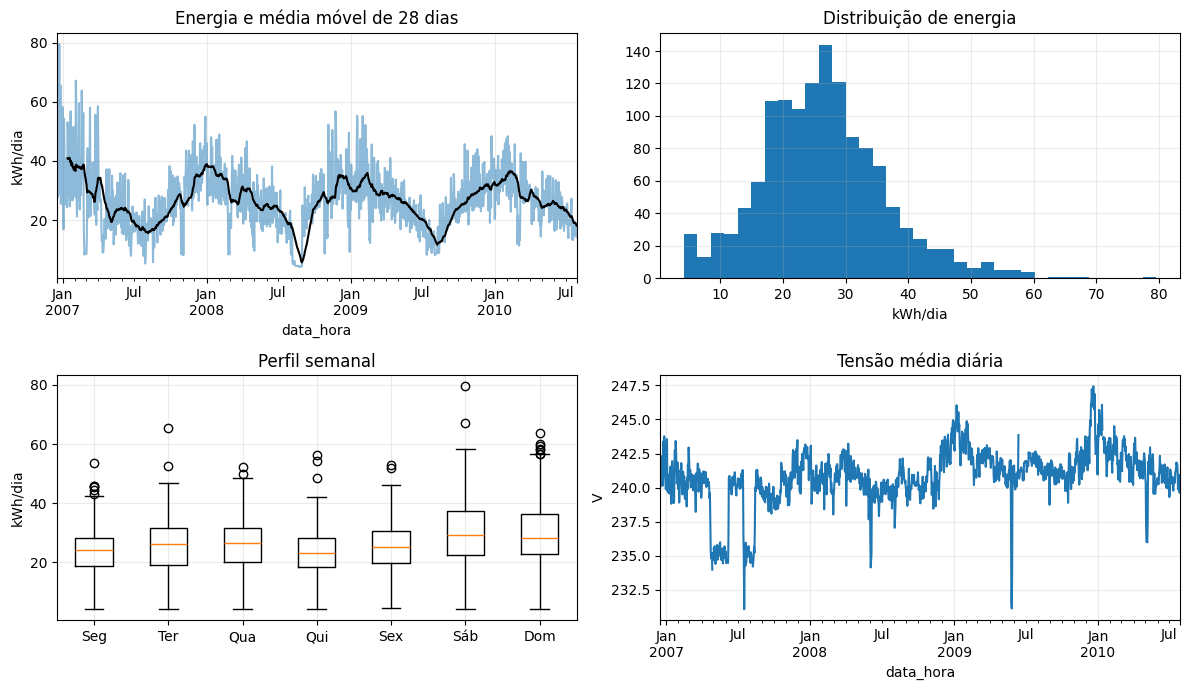

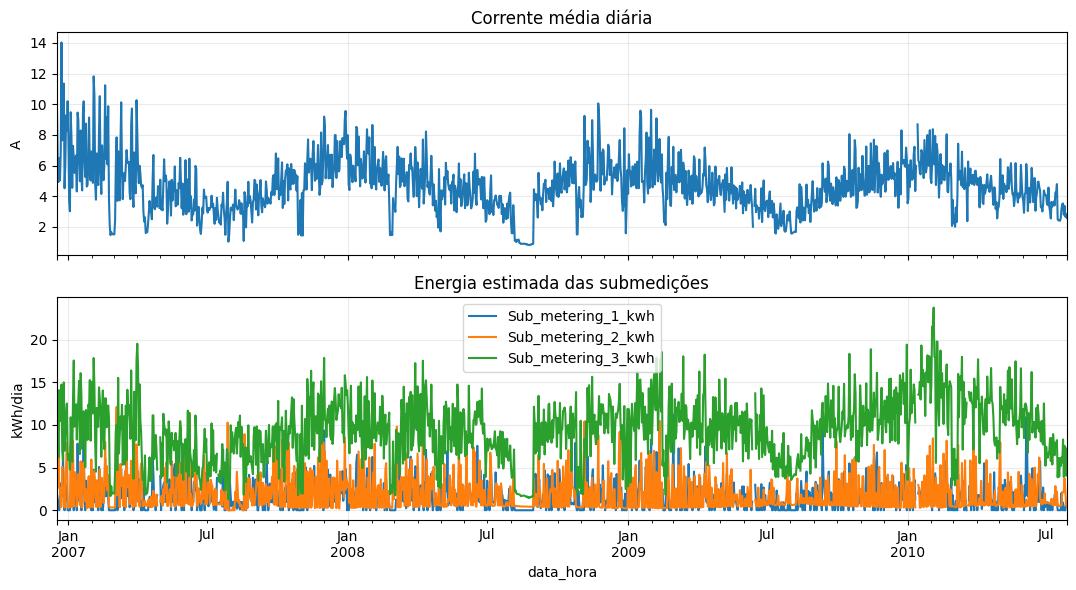

In [7]:
display(treino.describe().to_frame())
fig, ax = plt.subplots(2, 2, figsize=(12, 7))
treino.plot(ax=ax[0,0], alpha=.5, ylabel='kWh/dia', title='Energia e média móvel de 28 dias')
treino.rolling(28).mean().plot(ax=ax[0,0], color='black')
treino.hist(ax=ax[0,1], bins=35); ax[0,1].set(xlabel='kWh/dia', title='Distribuição de energia')
grupo = [treino[treino.index.dayofweek == d].values for d in range(7)]
ax[1,0].boxplot(grupo); ax[1,0].set(xticks=range(1,8), xticklabels=['Seg','Ter','Qua','Qui','Sex','Sáb','Dom'], ylabel='kWh/dia', title='Perfil semanal')
diario.loc[treino.index, 'Voltage'].plot(ax=ax[1,1], ylabel='V', title='Tensão média diária')
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(2,1, figsize=(11,6), sharex=True)
diario.loc[treino.index, 'Global_intensity'].plot(ax=ax[0], ylabel='A', title='Corrente média diária')
diario.loc[treino.index, [c+'_kwh' for c in ['Sub_metering_1','Sub_metering_2','Sub_metering_3']]].plot(ax=ax[1], ylabel='kWh/dia', title='Energia estimada das submedições')
plt.tight_layout(); plt.show()

## N08 • Decomposição, ACF, PACF e estacionariedade
STL com período 7 separa uma componente semanal, uma tendência suavizada e um restante. A decomposição é descritiva do treino e não fornece atributos para prever. Sua suavização pode usar vizinhos posteriores dentro desse bloco.

ACF mede associação com defasagens; PACF controla defasagens intermediárias. Picos não determinam automaticamente ordens de SARIMA. ADF tem hipótese nula de raiz unitária; KPSS, aqui com `regression='c'`, tem hipótese nula de estacionariedade em torno de um nível. Resultados devem ser analisados com gráficos, especificação e tamanho amostral. Diferenciar remove parte da informação de nível e pode ser excessivo.

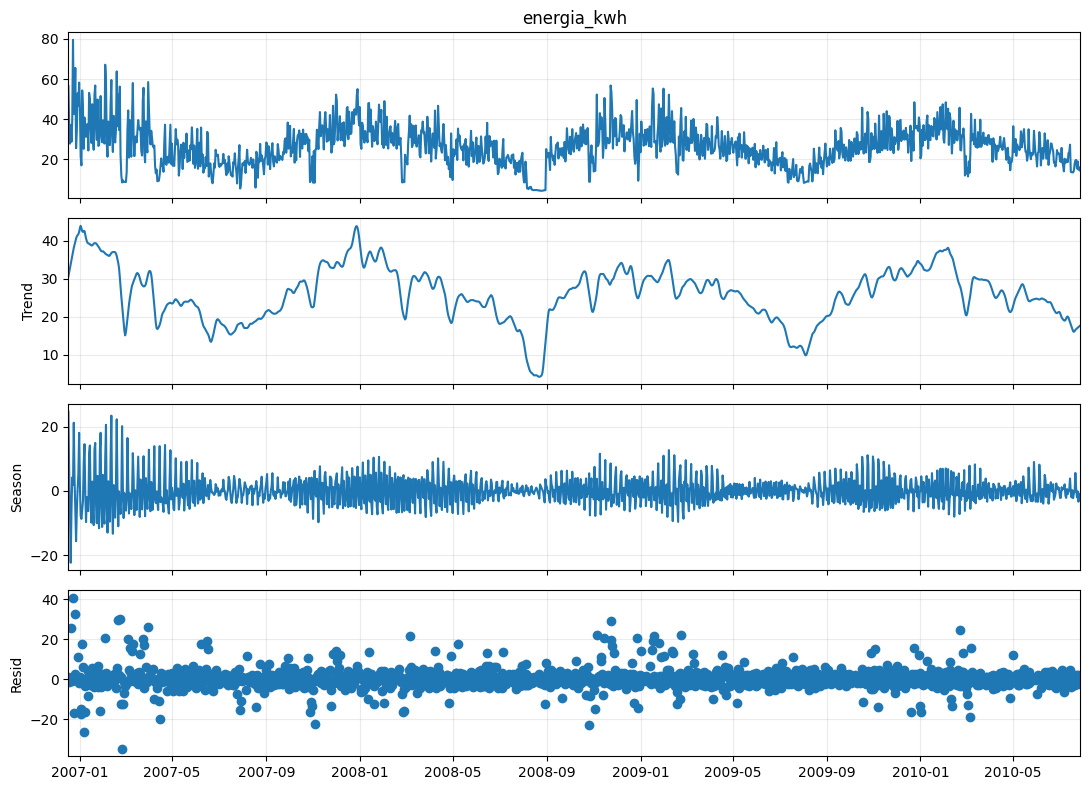

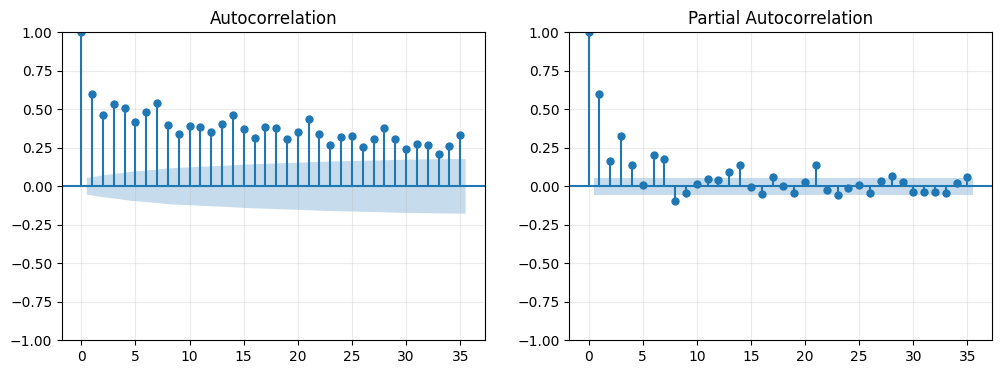

/tmp/ipykernel_4203/3859839063.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  a = adfuller(s, autolag='AIC')
/tmp/ipykernel_4203/3859839063.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  a = adfuller(s, autolag='AIC')
/tmp/ipykernel_4203/3859839063.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag argumen

,transformação,ADF p,KPSS p,nota KPSS
0,nível,1.286521e-02,0.1,The test statistic is outside of the range of ...
1,diferença de 1 dia,3.786140e-24,0.1,The test statistic is outside of the range of ...
2,diferença de 7 dias,6.977836e-19,0.1,The test statistic is outside of the range of ...


In [8]:
decomposicao = STL(treino, period=SAZONALIDADE, robust=True).fit()
decomposicao.plot(); plt.gcf().set_size_inches(11,8); plt.tight_layout(); plt.show()
fig, ax = plt.subplots(1,2, figsize=(12,4))
plot_acf(treino, lags=35, ax=ax[0]); plot_pacf(treino, lags=35, method='ywm', ax=ax[1]); plt.show()
linhas = []
for nome, s in [('nível', treino), ('diferença de 1 dia', treino.diff().dropna()), ('diferença de 7 dias', treino.diff(7).dropna())]:
    a = adfuller(s, autolag='AIC')
    with warnings.catch_warnings(record=True) as avisos:
        k = kpss(s, regression='c', nlags='auto')
    linhas.append({'transformação': nome, 'ADF p': a[1], 'KPSS p': k[1], 'nota KPSS': '; '.join(str(v.message) for v in avisos)})
display(pd.DataFrame(linhas))

## N09 • Transformação em problema supervisionado
Para prever o dia `t`, cada lag `k` representa `y[t-k]`. As médias e os desvios móveis usam `shift(1)` antes de `rolling`, excluindo `y[t]`. Dia da semana e mês são conhecidos antecipadamente e têm representação cíclica.

A função aceita lags e janelas diferentes e é reutilizada na previsão recursiva. O teste automatizado abaixo verifica que alterar o alvo e todo o seu futuro não altera os atributos daquele dia. Na validação principal, os atributos de dias posteriores podem incorporar valores já medidos em dias anteriores do bloco, pois o horizonte é um dia.

In [9]:
def atributos(serie, lags=None, janelas=None):
    lags = LAGS if lags is None else lags
    janelas = JANELAS if janelas is None else janelas
    X = pd.DataFrame(index=serie.index)
    for k in lags:
        X[f'lag_{k}'] = serie.shift(k)
    passado = serie.shift(1)
    for w in janelas:
        X[f'media_{w}'] = passado.rolling(w).mean()
        X[f'desvio_{w}'] = passado.rolling(w).std()
    dia = X.index.dayofweek; mes = X.index.month - 1
    X['semana_sin'] = np.sin(2*np.pi*dia/7); X['semana_cos'] = np.cos(2*np.pi*dia/7)
    X['mes_sin'] = np.sin(2*np.pi*mes/12); X['mes_cos'] = np.cos(2*np.pi*mes/12)
    return X
X = atributos(y)
data_verificacao = treino.index[-20]
modificada = y.copy(); modificada.loc[data_verificacao:] += 1000
np.testing.assert_allclose(X.loc[data_verificacao], atributos(modificada).loc[data_verificacao])
print('Verificação de causalidade dos atributos: aprovada.')
display(pd.concat([X, y], axis=1).dropna().head())

Verificação de causalidade dos atributos: aprovada.


,lag_1,lag_2,lag_3,lag_7,lag_14,lag_21,lag_28,media_7,desvio_7,media_28,desvio_28,semana_sin,semana_cos,mes_sin,mes_cos,energia_kwh
data_hora,,,,,,,,,,,,,,,,
2007-01-14,53.113567,24.354933,37.586567,40.793667,58.236600,42.500200,56.507667,37.181281,8.846565,40.916642,14.257696,-0.781831,0.623490,0.0,1.0,50.165104
2007-01-15,50.165104,53.113567,24.354933,37.356000,45.816733,45.718667,36.730433,38.520058,10.104077,40.690122,14.049685,0.000000,1.000000,0.0,1.0,35.811300
2007-01-16,35.811300,50.165104,53.113567,31.150900,21.153933,65.568500,27.769900,38.299386,10.150499,40.657296,14.060349,0.781831,0.623490,0.0,1.0,28.106733
2007-01-17,28.106733,35.811300,50.165104,35.913333,16.900900,25.479333,37.095800,37.864505,10.564573,40.669326,14.049054,0.974928,-0.222521,0.0,1.0,47.461467
2007-01-18,47.461467,28.106733,35.811300,37.586567,54.323533,34.543967,28.650192,39.514239,11.097331,41.039528,14.087919,0.433884,-0.900969,0.0,1.0,30.357700


## N10 • Modelos, métricas e função de avaliação
Os baselines são persistência (ontem) e ingênuo sazonal (sete dias antes). ETS modela nível e sazonalidade aditiva semanal. SARIMA usa `(1,0,1) × (1,0,0,7)`, uma configuração inicial fixa, não declarada ótima. Ridge é regressão linear regularizada; Random Forest agrega árvores; HistGradientBoosting constrói árvores sucessivas.

MAE e RMSE estão em kWh/dia. O viés é a média de `real - previsto`: positivo indica subestimação. MASE divide o MAE pelo erro médio do ingênuo sazonal no histórico de ajuste, usando pares observados. Não é preciso empregar MAPE, que pode ficar instável próximo de zero.

Todos recebem o mesmo histórico disponível. ETS é reajustado a cada origem; SARIMA mantém parâmetros e atualiza estados com `append`; ML mantém parâmetros e recebe atributos atualizados. Essa diferença deve ser registrada ao comparar custo. Não se omitem avisos de ajuste nem falhas.

In [10]:
modelos_ml = {
    'Ridge': make_pipeline(StandardScaler(), Ridge(alpha=10.0)),
    'Random Forest': RandomForestRegressor(n_estimators=120, min_samples_leaf=5, max_features=.8, random_state=SEMENTE, n_jobs=-1),
    'Boosting': HistGradientBoostingRegressor(max_iter=150, max_leaf_nodes=15, l2_regularization=2, random_state=SEMENTE)
}
NOMES = ['Persistência', 'Ingênuo sazonal', 'ETS', 'SARIMA', *modelos_ml]
def ajustar_sarima(serie):
    ajuste = SARIMAX(serie, order=(1,0,1), seasonal_order=(1,0,0,SAZONALIDADE), trend='c', enforce_stationarity=True, enforce_invertibility=True).fit(disp=False, maxiter=200)
    if not ajuste.mle_retvals.get('converged', False):
        warnings.warn('SARIMA não convergiu: interpretar resultado com cautela.')
    return ajuste

def metricas(real, previsto, historico):
    mascara = observado.reindex(real.index).fillna(False) & previsto.notna()
    erro = real[mascara] - previsto[mascara]
    pares = observado.reindex(historico.index).fillna(False) & observado.reindex(historico.index).shift(SAZONALIDADE, fill_value=False)
    escala = historico.diff(SAZONALIDADE).abs()[pares].mean()
    return {'n': len(erro), 'MAE': erro.abs().mean(), 'RMSE': np.sqrt((erro**2).mean()), 'viés': erro.mean(), 'MASE': erro.abs().mean()/escala if escala > 0 else np.nan}

def avaliar_bloco(historico, bloco, nomes=None):
    nomes = NOMES if nomes is None else nomes
    pred = pd.DataFrame(index=bloco.index, columns=nomes, dtype=float)
    ajustados = {}
    Xhist = atributos(historico); validas = Xhist.notna().all(axis=1) & observado.loc[historico.index]
    for nome in nomes:
        if nome in modelos_ml:
            ajustados[nome] = clone(modelos_ml[nome]).fit(Xhist.loc[validas], historico.loc[validas])
    estado = ajustar_sarima(historico) if 'SARIMA' in nomes else None
    atual = historico.copy()
    for data, valor_disponivel in bloco.items():
        if 'Persistência' in nomes: pred.loc[data, 'Persistência'] = atual.iloc[-1]
        if 'Ingênuo sazonal' in nomes: pred.loc[data, 'Ingênuo sazonal'] = atual.iloc[-SAZONALIDADE]
        if 'ETS' in nomes:
            ets = ExponentialSmoothing(atual, trend=None, seasonal='add', seasonal_periods=SAZONALIDADE, initialization_method='estimated').fit(optimized=True)
            pred.loc[data, 'ETS'] = ets.forecast(1).iloc[0]
        if estado is not None: pred.loc[data, 'SARIMA'] = estado.forecast(1).iloc[0]
        contexto = pd.concat([atual, pd.Series([np.nan], index=pd.DatetimeIndex([data]))]).asfreq('D')
        linha = atributos(contexto).loc[[data]]
        for nome, modelo in ajustados.items(): pred.loc[data, nome] = modelo.predict(linha)[0]
        novo = pd.Series([valor_disponivel], index=pd.DatetimeIndex([data]), name='energia_kwh').asfreq('D')
        atual = pd.concat([atual, novo]).asfreq('D')
        if estado is not None: estado = estado.append(novo, refit=False)
    tabela = pd.DataFrame({nome: metricas(bloco, pred[nome], historico) for nome in nomes}).T.sort_values('MAE')
    return pred, tabela
print('Modelos e funções prontos.')

Modelos e funções prontos.


## N11 • Validação temporal e seleção
Primeiro, três divisões crescentes dentro do treino avaliam a estabilidade do Random Forest. Cada validação é de um passo, com acesso apenas às observações anteriores de seu próprio bloco. Os atributos da validação podem aproveitar o passado já conhecido; o ajuste de parâmetros usa somente o treino da divisão.

Depois, todos os modelos são comparados nos 60 dias de validação. O nome com menor MAE é congelado antes de abrir o teste. Não se muda a escolha pelo resultado do teste. As configurações dos modelos foram fixadas para facilitar a aula; esta não é uma busca exaustiva de hiperparâmetros.

In [11]:
Xt = X.loc[treino.index].dropna(); yt = treino.loc[Xt.index]
cv = TimeSeriesSplit(n_splits=3, test_size=30)
resultados_cv = []
for fold, (i_tr, i_va) in enumerate(cv.split(Xt), 1):
    idx_tr = Xt.index[i_tr]; idx_va = Xt.index[i_va]
    validos_tr = observado.loc[idx_tr]
    m = clone(modelos_ml['Random Forest']).fit(Xt.loc[idx_tr[validos_tr]], yt.loc[idx_tr[validos_tr]])
    pr = pd.Series(m.predict(Xt.loc[idx_va]), index=idx_va)
    resultados_cv.append({'divisão': fold, 'treino_até': idx_tr[-1].date(), 'validação_de': idx_va[0].date(), **metricas(yt.loc[idx_va], pr, treino.loc[:idx_tr[-1]])})
display(pd.DataFrame(resultados_cv))
pred_validacao, tabela_validacao = avaliar_bloco(treino, validacao)
escolhido = tabela_validacao.index[0]
display(tabela_validacao.round(3)); print('Modelo escolhido somente pela validação:', escolhido)

,divisão,treino_até,validação_de,n,MAE,RMSE,viés,MASE
0,1,2010-04-29,2010-04-30,30,3.473599,4.567743,0.767430,0.490879
1,2,2010-05-29,2010-05-30,30,3.351645,4.141997,-0.574830,0.477077
2,3,2010-06-28,2010-06-29,30,3.099295,3.705223,-0.687583,0.446616


,n,MAE,RMSE,viés,MASE
ETS,52.0,3.243,4.806,0.626,0.471
Boosting,52.0,3.270,4.600,0.077,0.475
Persistência,52.0,3.420,5.253,0.173,0.497
Random Forest,52.0,3.582,4.494,-0.419,0.520
SARIMA,52.0,3.780,4.827,-1.228,0.549
Ridge,52.0,4.081,5.119,-0.946,0.593
Ingênuo sazonal,52.0,5.595,7.407,0.692,0.813


Modelo escolhido somente pela validação: ETS


## N12 • Teste final de um passo à frente
Os modelos são ajustados em treino + validação e avaliados no bloco final. A linha do escolhido é a avaliação da regra de seleção previamente definida. A tabela com todos os modelos serve para comparação didática; escolher novamente pelo teste contaminaria uma avaliação final subsequente.

O percentual de melhoria usa MAE do ingênuo sazonal como referência: valor positivo indica menor erro. Resultados dependem da residência, da cobertura e do período. Não se pressupõe que ML vencerá métodos clássicos.

,n,MAE,RMSE,viés,MASE,melhoria_vs_sazonal_%
Boosting,58.0,4.948,6.811,-0.425,0.726,36.138
Random Forest,58.0,5.197,6.780,0.052,0.763,32.928
ETS,58.0,5.258,7.107,0.364,0.771,32.139
Ridge,58.0,5.545,7.147,0.173,0.814,28.433
SARIMA,58.0,5.641,7.585,0.511,0.828,27.193
Persistência,58.0,6.377,8.809,0.092,0.936,17.689
Ingênuo sazonal,58.0,7.748,9.943,0.651,1.137,0.000


Avaliação do modelo selecionado: ETS


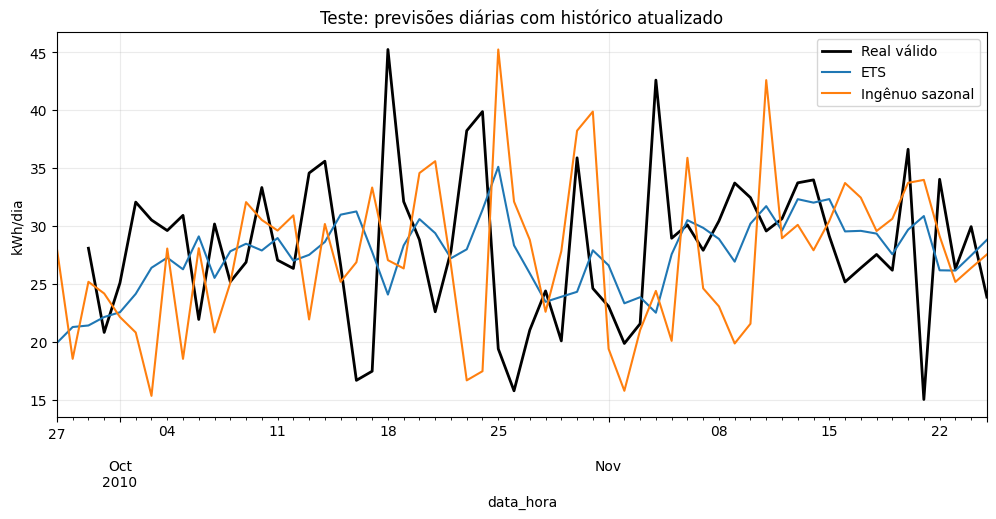

In [12]:
desenvolvimento = y.iloc[:fim_validacao]
pred_teste, tabela_teste = avaliar_bloco(desenvolvimento, teste)
mae_base = tabela_teste.loc['Ingênuo sazonal', 'MAE']
tabela_teste['melhoria_vs_sazonal_%'] = 100 * (1 - tabela_teste['MAE']/mae_base) if mae_base > 0 else np.nan
display(tabela_teste.round(3)); print('Avaliação do modelo selecionado:', escolhido)
fig, ax = plt.subplots(figsize=(12,5))
teste.where(observado.loc[teste.index]).plot(ax=ax, color='black', label='Real válido', linewidth=2)
for nome in [escolhido, 'Ingênuo sazonal']:
    if nome not in [l.get_label() for l in ax.lines]: pred_teste[nome].plot(ax=ax, label=nome)
ax.set(ylabel='kWh/dia', title='Teste: previsões diárias com histórico atualizado'); ax.legend(); plt.show()

## N13 • Diagnóstico e interpretação física
Erros fora da amostra são diferentes dos resíduos de ajuste. Média próxima de zero não basta: autocorrelação pode revelar estrutura não capturada, e erros maiores em picos podem ser operacionalmente relevantes. Ljung-Box avalia ausência conjunta de autocorrelação até os lags indicados; valores pequenos sugerem dependência.

Para manter espaçamento diário, a ACF e o Ljung-Box abaixo usam o maior segmento contínuo de erros com alvo válido. Não se comprimem lacunas como se dias distantes fossem consecutivos. A amostra final é pequena, portanto testes têm limitações. Os limites do SARIMA aparecerão separadamente em N14.

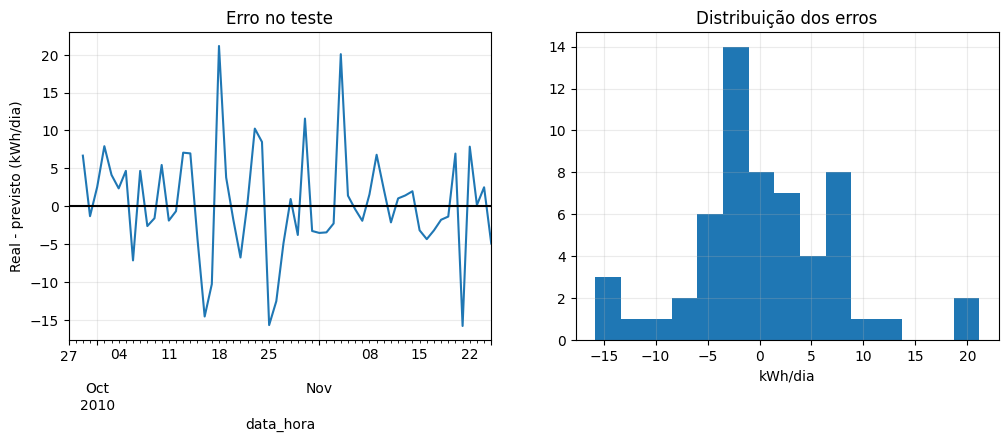

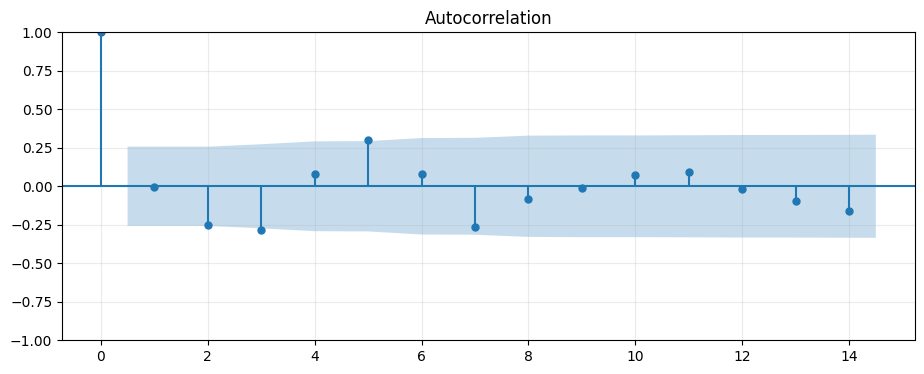

,lb_stat,lb_pvalue
7,20.542609,0.004510
14,24.815554,0.036433


Dias com maior erro absoluto válido:


,real,previsto,erro
data_hora,,,
2010-10-18,45.231400,24.072639,21.158761
2010-11-04,42.585767,22.507050,20.078716
2010-11-21,15.015167,30.851294,-15.836127
2010-10-25,19.388200,35.103455,-15.715255
2010-10-16,16.666900,31.249374,-14.582474


In [13]:
erros = (teste - pred_teste[escolhido]).where(observado.loc[teste.index])
fig, ax = plt.subplots(1,2, figsize=(12,4))
erros.plot(ax=ax[0], ylabel='Real - previsto (kWh/dia)', title='Erro no teste'); ax[0].axhline(0, color='black')
erros.dropna().hist(ax=ax[1], bins=15); ax[1].set(title='Distribuição dos erros', xlabel='kWh/dia'); plt.show()
grupos = erros.notna().ne(erros.notna().shift()).cumsum()
segmentos = [s.dropna() for _, s in erros.groupby(grupos) if s.notna().all()]
segmento = max(segmentos, key=len)
if len(segmento) > 15:
    plot_acf(segmento, lags=min(14, len(segmento)//2-1)); plt.show()
    display(acorr_ljungbox(segmento, lags=[7,14], return_df=True))
else: print('Poucos erros consecutivos para diagnóstico de autocorrelação.')
comparacao = pd.DataFrame({'real': teste, 'previsto': pred_teste[escolhido], 'erro': erros})
print('Dias com maior erro absoluto válido:')
display(comparacao.loc[erros.abs().nlargest(5).index])
if escolhido in modelos_ml:
    xx = atributos(desenvolvimento); mascara = xx.notna().all(axis=1) & observado.loc[xx.index]
    modelo_diagnostico = clone(modelos_ml[escolhido]).fit(xx.loc[mascara], desenvolvimento.loc[mascara])
    if escolhido == 'Random Forest':
        display(pd.Series(modelo_diagnostico.feature_importances_, index=xx.columns).sort_values(ascending=False).to_frame('importância por impureza'))
        print('Importância indica uso preditivo no modelo, não causalidade; atributos correlacionados dividem relevância.')

## N14 • Previsão de vários dias sem novas medições
Agora a origem fica fixa. Durante os 14 passos, valores reais futuros não estão disponíveis. Persistência e sazonal ingênuo repetem o histórico; ETS e SARIMA fazem previsão de horizonte completo; ML realimenta suas próprias previsões nos lags e nas janelas.

Primeiro é feita uma comparação retrospectiva de 14 dias a partir do início do teste, sem atualização por valores reais. Seu MAE não é diretamente comparável ao teste completo de um passo. Depois os modelos são reajustados no histórico inteiro e projetam os dias seguintes à última data do arquivo. **Essas datas são de 2010, não representam os próximos dias da data atual.**

O intervalo de 95% é do SARIMA e depende das hipóteses desse modelo. Não é intervalo de confiança da média nem garantia física. Cobertura será medida no retrospecto, apenas onde há alvo válido. Se os limites forem negativos, serão exibidos: truncar exigiria revisar a interpretação probabilística.

,n,MAE,RMSE,viés,MASE
ETS: origem fixa,12,7.856814,8.597545,7.856814,1.152863


Cobertura empírica do intervalo SARIMA no retrospecto: 100.0 %; n = 12


,modelo_escolhido_kwh,sarima_kwh,inferior_95,superior_95
2010-11-26,26.24,26.31,12.18,40.45
2010-11-27,29.33,28.84,14.14,43.54
2010-11-28,27.02,23.60,8.43,38.76
2010-11-29,28.19,28.20,12.66,43.74
2010-11-30,25.57,26.32,10.46,42.18
2010-12-01,27.01,27.20,11.08,43.32
2010-12-02,27.52,25.72,9.39,42.06
2010-12-03,26.24,26.31,8.96,43.67
2010-12-04,29.33,26.92,9.27,44.58
2010-12-05,27.02,25.65,7.75,43.55


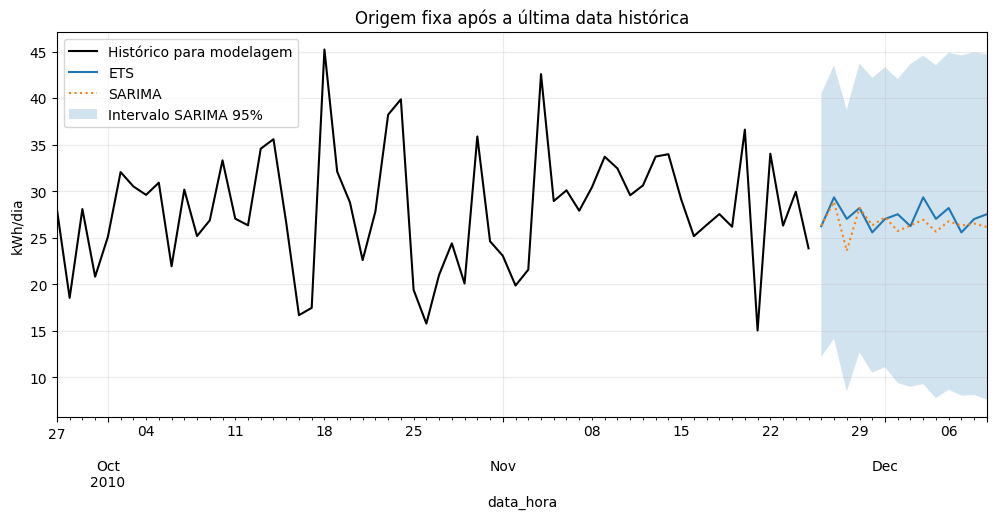

In [14]:
def prever_multiplos(nome, historico, horizonte):
    datas = pd.date_range(historico.index[-1]+pd.Timedelta(days=1), periods=horizonte, freq='D')
    if nome == 'ETS':
        m = ExponentialSmoothing(historico, trend=None, seasonal='add', seasonal_periods=SAZONALIDADE, initialization_method='estimated').fit()
        return pd.Series(np.asarray(m.forecast(horizonte)), index=datas), None
    if nome == 'SARIMA':
        f = ajustar_sarima(historico).get_forecast(horizonte)
        return pd.Series(np.asarray(f.predicted_mean), index=datas), pd.DataFrame(np.asarray(f.conf_int(alpha=.05)), index=datas, columns=['inferior_95', 'superior_95'])
    m = None
    if nome in modelos_ml:
        xx = atributos(historico); ok = xx.notna().all(axis=1) & observado.loc[historico.index]
        m = clone(modelos_ml[nome]).fit(xx.loc[ok], historico.loc[ok])
    atual = historico.copy(); previsoes = []
    for data in datas:
        if nome == 'Persistência': valor = atual.iloc[-1]
        elif nome == 'Ingênuo sazonal': valor = atual.iloc[-SAZONALIDADE]
        else:
            contexto = pd.concat([atual, pd.Series([np.nan], index=[data])]).asfreq('D')
            valor = m.predict(atributos(contexto).loc[[data]])[0]
        previsoes.append(valor)
        atual = pd.concat([atual, pd.Series([valor], index=[data])]).asfreq('D')
    return pd.Series(previsoes, index=datas), None
retrospecto = teste.iloc[:HORIZONTE_FUTURO]
pr_multi, _ = prever_multiplos(escolhido, desenvolvimento, len(retrospecto))
pr_sarima_multi, intervalo_retro = prever_multiplos('SARIMA', desenvolvimento, len(retrospecto))
display(pd.DataFrame([metricas(retrospecto, pr_multi, desenvolvimento)], index=[escolhido + ': origem fixa']))
mask = observado.loc[retrospecto.index]
cobertura = ((retrospecto >= intervalo_retro.inferior_95) & (retrospecto <= intervalo_retro.superior_95))[mask].mean()
print('Cobertura empírica do intervalo SARIMA no retrospecto:', round(100*cobertura, 1), '%; n =', int(mask.sum()))
futuro, _ = prever_multiplos(escolhido, y, HORIZONTE_FUTURO)
futuro_sarima, intervalo_futuro = prever_multiplos('SARIMA', y, HORIZONTE_FUTURO)
saida_futuro = pd.DataFrame({'modelo_escolhido_kwh': futuro, 'sarima_kwh': futuro_sarima}).join(intervalo_futuro)
display(saida_futuro.round(2))
fig, ax = plt.subplots(figsize=(12,5))
y.iloc[-60:].plot(ax=ax, color='black', label='Histórico para modelagem')
futuro.plot(ax=ax, label=escolhido); futuro_sarima.plot(ax=ax, label='SARIMA', linestyle=':')
ax.fill_between(intervalo_futuro.index, intervalo_futuro.inferior_95, intervalo_futuro.superior_95, alpha=.2, label='Intervalo SARIMA 95%')
ax.set(ylabel='kWh/dia', title='Origem fixa após a última data histórica'); ax.legend(); plt.show()

## N15 • Exportação e reprodutibilidade
Os arquivos registram métricas, previsões e qualidade. O notebook também registra versões e parâmetros. O ZIP de exportação contém tabelas, não os dados brutos da UCI. Em Colab, os arquivos podem ser obtidos no painel lateral; a última célula apenas oferece o download, sem alterar modelos.

In [15]:
diario.assign(energia_modelagem_kwh=y, alvo_valido=observado).to_csv(PASTA/'serie_diaria.csv')
tabela_validacao.to_csv(PASTA/'metricas_validacao.csv')
tabela_teste.to_csv(PASTA/'metricas_teste.csv')
pred_teste.assign(real_kwh=teste, alvo_valido=observado.loc[teste.index]).to_csv(PASTA/'previsoes_teste.csv')
saida_futuro.to_csv(PASTA/'previsoes_origem_fixa.csv')
configuracao = {'fonte': URL, 'cobertura_minima': COBERTURA_MINIMA, 'lags': LAGS, 'janelas': JANELAS, 'validacao_dias': VALIDACAO_DIAS, 'teste_dias': TESTE_DIAS, 'modelo_selecionado_na_validacao': escolhido, 'versoes': {'python': platform.python_version(), 'pandas': pd.__version__, 'sklearn': sklearn.__version__, 'statsmodels': statsmodels.__version__}}
(PASTA/'configuracao.json').write_text(json.dumps(configuracao, ensure_ascii=False, indent=2), encoding='utf-8')
with zipfile.ZipFile(PASTA/'resultados_series.zip', 'w', compression=zipfile.ZIP_DEFLATED) as z:
    for f in sorted(PASTA.iterdir()):
        if f.suffix in ['.csv','.json']: z.write(f, arcname=f.name)
print('Resultados salvos em:', PASTA.resolve())

Resultados salvos em: /content/series_eletricas


## N16 • Células para o estudo dirigido
O PDF de atividades especifica quais alterações executar. Criar células abaixo desta seção para registrar hipóteses, trechos alterados, tabelas e interpretação. Preservar os resultados originais antes de modificar configurações.

Para alterações de atributos, comparar modelos na **validação**, usando a mesma máscara de alvos. Não utilizar o teste para escolher a configuração. Uma nova configuração exige reexecutar N09 a N11. Alterar cobertura exige reexecutar N04 em diante. Não é necessário repetir o download.

### Experimento controlado de lags
A célula seguinte compara o Random Forest original com uma versão sem o calendário nem janelas, usando lags 1 e 7. Os modelos são ajustados no mesmo subconjunto de treino. A avaliação mantém o protocolo de um passo. Substituir `[1, 7]` pela configuração solicitada e justificar a hipótese antes de executar.

In [16]:
def experimento_lags(lags_novos):
    Xoriginal = atributos(y)
    Xnovo = atributos(y, lags=lags_novos, janelas=[])
    Xnovo = Xnovo[[f'lag_{k}' for k in lags_novos]]
    comum = Xoriginal.loc[treino.index].notna().all(axis=1) & Xnovo.loc[treino.index].notna().all(axis=1) & observado.loc[treino.index]
    datas_treino = treino.index[comum]
    resultados = {}
    for nome, xx in [('Original', Xoriginal), ('Lags modificados', Xnovo)]:
        m = clone(modelos_ml['Random Forest']).fit(xx.loc[datas_treino], y.loc[datas_treino])
        prev = pd.Series(m.predict(xx.loc[validacao.index]), index=validacao.index)
        resultados[nome] = metricas(validacao, prev, treino)
    return pd.DataFrame(resultados).T
# Descomentar durante a atividade:
# display(experimento_lags([1, 7]).round(3))

### Registro da interpretação
Preencher após os experimentos: unidade e alvo; cobertura e imputação; padrão observado no treino; hipótese de alteração; métricas antes/depois; modelo escolhido pela validação; diferença entre um passo e origem fixa; limitações para uso em outra instalação.

### Referências de consulta
[Base UCI e dicionário](https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption) · [SARIMAX](https://www.statsmodels.org/stable/generated/statsmodels.tsa.statespace.sarimax.SARIMAX.html) · [Suavização exponencial](https://www.statsmodels.org/stable/generated/statsmodels.tsa.holtwinters.ExponentialSmoothing.html) · [STL](https://www.statsmodels.org/stable/generated/statsmodels.tsa.seasonal.STL.html) · [TimeSeriesSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html) · [Atributos defasados](https://scikit-learn.org/stable/auto_examples/applications/plot_time_series_lagged_features.html).

Material teórico correspondente: *Séries temporais na Engenharia Elétrica*. Atividades: *Estudo dirigido de séries temporais: 120 minutos*.